# Analysing S(Q,$\omega$)


In order to analyse S(Q,w) we need to calculate it, this can be done using MDANSE. 

When we run MDANSE we need to think about a few things:

* What kind of length scale I am interested in?
* What kind of energy exchange I am interested in?
* What kind of simulation sampling do I need to match this energy exchange / length scale and ensure my results are converged? 

The [documentation](https://mdanse.readthedocs.io/en/latest/how_to_guides/H_conv.html) can be very helpful for this!


Have a crack at running the 1ns trajectory through MDANSE to calculate $S_{inc}$(Q,$\omega$). 
(If this is taking ages the output has also been provided for you in ```Data/benzene```)


For reference we are going to be comparing this to two experimental QENS datasets both taken from the ISIS neutron and muon source 

One from the unpolarised indirect geometry spectrometer [IRIS](https://www.isis.stfc.ac.uk/instruments/iris/) using the PG 002 crystal.

and one from the polarised direct geomtry spectrometer [LET](https://www.isis.stfc.ac.uk/instruments/let/)  (Q ~ 0.5-2 $Å^{-1}$, $\omega$ ~ -2 - 2 meV).



Once you have had a go at generating S(Q,w), we can load and plot the output with the below code!


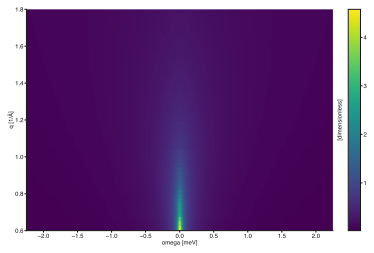

In [73]:
import h5py
from pathlib import Path
import scipp as sc
import matplotlib.pyplot as plt
import numpy as np
from _fig_params import colors

DATA = Path("../../Data/benzene")
MDA = DATA / "incoh.mda"
COMP = "total"
HBAR = 0.6582119569  # meV per rad/ps

inc = {}
with h5py.File(MDA, "r") as f:
    inc["q"] = f["disf/axes/q"][...] / 10
    inc["omega"] = f["disf/axes/omega"][...] * HBAR
    inc["S"] = f[f"disf/s(q,f)/{COMP}"][...] / HBAR


def create_scipp_array(S, q, omega):
    half_bin_omega = (np.diff(omega) / 2)[0]
    omega = np.append(omega - half_bin_omega, omega[-1] + half_bin_omega)

    half_bin_q = (np.diff(q) / 2)[0]
    q = np.append(q - half_bin_q, q[-1] + half_bin_q)

    sqw = sc.DataArray(
        data=sc.array(dims=["q", "omega"], values=inc["S"]),
        coords={
            "q": sc.array(dims=["q"], values=q, unit="1/Angstrom"),
            "omega": sc.array(dims=["omega"], values=omega, unit="meV"),
        },
    )
    return sqw


sqw = create_scipp_array(inc["S"], inc["q"], inc["omega"])
q_bins = sc.linspace("q", 0.6, 1.8, num=50, unit="1/Angstrom")
omega_bins = sc.linspace("omega", -2.25, 2.25, num=1000, unit="meV")
bin_dict = {"q": q_bins, "omega": omega_bins}
sqw.rebin(**bin_dict).plot()

We can also have a look at a few individual Q, we see the spectra widening and the intensity dropping as a function of Q

Text(0.5, 0, '$\\omega$ / meV')

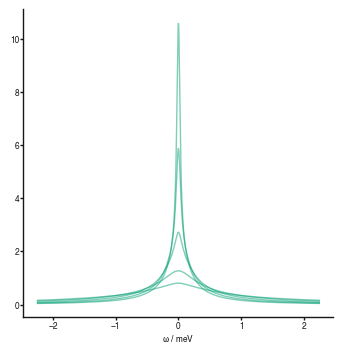

In [72]:
q_bins = sc.linspace("q", 0.6, 1.8, num=20, unit="1/Angstrom")
omega_bins = sc.linspace("omega", -2.25, 2.25, num=1000, unit="meV")
bin_dict = {"q": q_bins, "omega": omega_bins}
inc = sqw.rebin(**bin_dict)

fig, ax = plt.subplots(figsize=(4, 4))
ax = [ax]

for i in [0, 2, 5, 10, 15]:
    ax[0].plot(
        sc.midpoints(inc.coords["omega"]), inc.data["q", i], color=colors[1], alpha=0.5
    )

ax[0].set_xlabel(r"$\omega$ / meV")

Have a play binning some of the data and making some plots